In [13]:
import pandas as pd
pd.options.display.float_format = "{:,.0f}".format
import matplotlib.pyplot as plt

In [14]:
dgs1 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1", index_col=0, parse_dates=True, na_values=".")
dgs2 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS2", index_col=0, parse_dates=True, na_values=".")
dgs7 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS7", index_col=0, parse_dates=True, na_values=".")
dgs10 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10", index_col=0, parse_dates=True, na_values=".")
dtb3 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTB3", index_col=0, parse_dates=True, na_values=".")

In [15]:
yields = pd.concat([dgs1, dgs2, dgs7, dgs10, dtb3], axis=1).loc["2000-01-01":].dropna()
yields_m = yields.resample("ME").last()
yields_m["spread_bp"] = (yields_m["DGS10"] - yields_m["DGS2"]) * 100
yields_m.head()

,DGS1,DGS2,DGS7,DGS10,DTB3,spread_bp
observation_date,,,,,,
2000-01-31,6,7,7,7,6,7
2000-02-29,6,7,7,6,6,-11
2000-03-31,6,6,6,6,6,-47
2000-04-30,6,7,6,6,6,-45
2000-05-31,6,7,7,6,5,-40


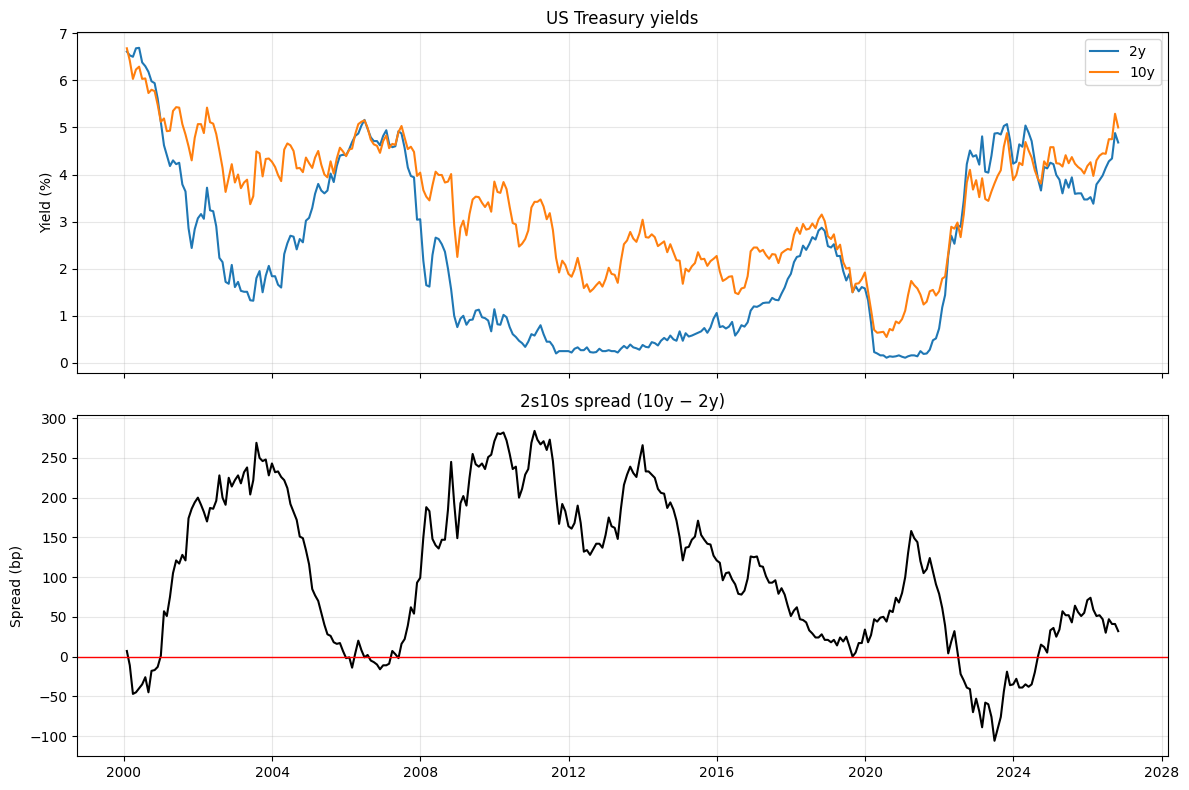

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(yields_m.index, yields_m["DGS2"], label="2y")
ax1.plot(yields_m.index, yields_m["DGS10"], label="10y")
ax1.set_ylabel("Yield (%)")
ax1.set_title("US Treasury yields")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(yields_m.index, yields_m["spread_bp"], color="black")
ax2.axhline(0, color="red", linewidth=1)
ax2.set_ylabel("Spread (bp)")
ax2.set_title("2s10s spread (10y − 2y)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
DV01 = 10_000
yields_m["spread_pnl"] = DV01 * yields_m["spread_bp"].diff()
yields_m["spread_pnl_cum"] = yields_m["spread_pnl"].cumsum()
yields_m["roll"] = (DV01 * ((yields_m["DGS2"] - yields_m["DGS1"]) - (yields_m["DGS10"] - yields_m["DGS7"]) / 3) * 100 / 12).shift(1)

In [18]:
yields_m["roll"] = (DV01 * ((yields_m["DGS2"] - yields_m["DGS1"]) - (yields_m["DGS10"] - yields_m["DGS7"]) / 3) * 100 / 12).shift(1)

In [19]:
y2 = yields_m["DGS2"] / 100
y10 = yields_m["DGS10"] / 100
r = yields_m["DTB3"] / 100

yields_m["notional_2"] = DV01 / ((1 / y2) * (1 - 1 / (1 + y2 / 2) ** 4) * 1e-4)
yields_m["notional_10"] = DV01 / ((1 / y10) * (1 - 1 / (1 + y10 / 2) ** 20) * 1e-4)

yields_m["carry"] = ((yields_m["notional_2"] * (y2 - r) - yields_m["notional_10"] * (y10 - r)) / 12).shift(1)

In [20]:
yields_m[["spread_bp", "spread_pnl", "roll", "carry"]].tail(24)

,spread_bp,spread_pnl,roll,carry
observation_date,,,,
2024-11-30,5,"-70,000","-11,111","-10,627"
2024-12-31,33,"280,000","-16,389","-9,239"
2025-01-31,36,"30,000","4,722","-2,790"
2025-02-28,25,"-110,000","1,111","-3,105"
2025-03-31,34,"90,000","-10,278","-9,603"
2025-04-30,57,"230,000","-15,556","-14,194"
2025-05-31,52,"-50,000","-27,500","-25,827"
2025-06-30,52,0,"-24,722","-17,400"
2025-07-31,43,"-90,000","-27,222","-22,683"


In [21]:
(yields_m["carry"].dropna() < 0).mean()

np.float64(0.5295950155763239)

In [22]:
yields_m["carry_roll"] = yields_m["carry"] + yields_m["roll"]
yields_m["total"] = yields_m["spread_pnl"] + yields_m["carry_roll"]

pnl = yields_m[["spread_pnl", "carry", "roll", "carry_roll", "total"]].dropna()
pnl.sum()

spread_pnl     250,000
carry          464,972
roll         1,870,833
carry_roll   2,335,805
total        2,585,805
dtype: float64